## Analysis of CRISPR-Cas9-induced lineage barcode creation dynamics in early development

In [2]:
library(ggrepel)
library(ggplot2)
library(plyr)
library(dplyr)
library(tidyr) 
library(DescTools)
library(pheatmap)
library(ggbeeswarm)
library(forcats)

source("/local/users/nfresma/Scripts/sc_DR_NB_functions.r")

wd <- 'data/'

### Load DNA-based results

In [45]:
# Load data
sample_vals_all <- read.delim('data/all_DNA_scars_summarized.csv', stringsAsFactors = F, header = T, sep = ',', row.names = 1)
wt_sum_all <- read.delim('data/DNA_based_wt_fraction_per_sample.csv', stringsAsFactors = F, header = T, sep = ',', row.names = 1)


In [46]:
# Load and process sample info
sample_info <- read.delim('data/sample_ids_DNA_scarDyn_02.csv',sep = ';')

sample_names <- c(sample_info$sample_name_actb1, sample_info$sample_name_rpl39, sample_info$sample_name_dsRRC)

sample_info_actb1 <- sample_info[,c('inj_cond','hpf','cross','sample_name_actb1')]
sample_info_rpl39 <- sample_info[,c('inj_cond','hpf','cross','sample_name_rpl39')]
sample_info_dsRRC <- sample_info[,c('inj_cond','hpf','cross','sample_name_dsRRC')]

colnames(sample_info_actb1) <- c('inj_cond','hpf','cross','sample_id')
colnames(sample_info_rpl39) <- c('inj_cond','hpf','cross','sample_id')
colnames(sample_info_dsRRC) <- c('inj_cond','hpf','cross','sample_id')

sample_info_all <- rbind(sample_info_actb1, sample_info_rpl39, sample_info_dsRRC)

In [47]:
# Merge data with metadata and clean before plot

wt_sum_all_meta <- left_join(wt_sum_all, sample_info_all, by = 'sample_id')

wt_sum_all_meta$fraction_wt <- as.numeric(wt_sum_all_meta$fraction_wt)
wt_sum_all_meta$fraction_nonwt <- as.numeric(wt_sum_all_meta$fraction_nonwt)
wt_sum_all_meta$fraction_wt[is.na(wt_sum_all_meta$fraction_wt)] <- 0
wt_sum_all_meta$fraction_nonwt[is.na(wt_sum_all_meta$fraction_nonwt)] <- 0

# remove timepoint at which no RNA-sample was taken
wt_sum_all_meta <- wt_sum_all_meta[wt_sum_all_meta$hpf != '9,5',]
wt_sum_all_meta$hpf <- as.numeric(wt_sum_all_meta$hpf)
wt_sum_all_meta <- wt_sum_all_meta[!wt_sum_all_meta$sample_id %in% c('actb1_s1_TTGA','rpl39_s1_CGAA','dsRRC_s1_TAGT'),]

unique(wt_sum_all_meta$hpf)

[1]  1  2  3  4  5  6  7  8  9 10 11 26

### Load RNA-based results

In [48]:
RNA_vals <- read.delim('data/wt_fractions_summarized_RNAscardyn.csv', sep = ',', stringsAsFactors = F, row.names = 1)


#### Merge both and plot

In [49]:
# Make dataframes compatible and merge
wt_sum_all_meta <- wt_sum_all_meta[,c('sample_id','fraction_wt','hpf','inj_cond')]
RNA_vals <- RNA_vals[,c('sample_id','fraction_wt','hpf','inj_cond')]

wt_sum_all_meta$type <- 'DNA'
RNA_vals$type <- 'RNA'


In [50]:
wt_sum_all_meta$hpf <- as.numeric(wt_sum_all_meta$hpf)
all_vals <- rbind(wt_sum_all_meta, RNA_vals)

all_vals$hpf <- as.character(all_vals$hpf)
all_vals$hpf[all_vals$hpf %in% c('24','26')] <- '24'
all_vals$type[all_vals$inj_cond == 'uninjected'] <- 'ctrl'

# Remove individual control value
all_vals$hpftype <- paste0(all_vals$hpf, all_vals$type)
all_vals <- all_vals[all_vals$hpftype != 'ctrl',]

In [51]:
# EXTENDED TO MATCH THE DBH DYN
all_vals$hpf <- factor(all_vals$hpf, levels = as.character(c(1:12,14,16,18,21,24)))
all_vals$type <- factor(all_vals$type, levels = c('DNA','RNA','ctrl'))


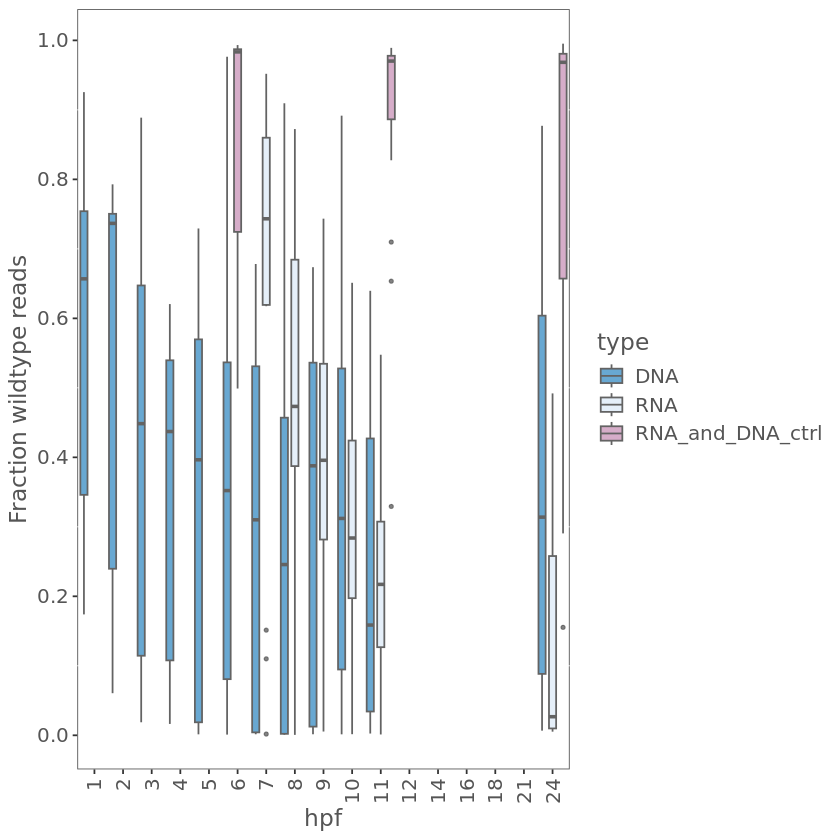

In [53]:
# Plot

ggplot(all_vals, aes(x = hpf, y = fraction_wt)) +
    geom_boxplot(aes(fill = type), position = position_dodge(width = 1.1, preserve = "single"), color = '#636363', alpha = 0.8, outlier.size=0.8) +
    scale_fill_manual(values = c('#4292C6','#DEEBF7', '#CC99BB'), labels = c('DNA','RNA','RNA_and_DNA_ctrl')) +
    scale_y_continuous(breaks = round(seq(0, 1, by = 0.2),1)) +
    scale_x_discrete(drop = FALSE) +  # Important: keeps unused factor levels
    labs(y = paste0('Fraction wildtype reads'), x = 'hpf') +
    mytheme_angledX



In [56]:
# Save source data

all_vals_dat <- all_vals[,!colnames(all_vals) %in% c('inj_cond','hpftype')]

write.csv(all_vals_dat, 'source_data_figs/source_data_2c.csv', quote = F, row.names = F)
